# 0a

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D

plt.rcParams['figure.figsize'] = (8,6)
plt.rcParams['font.size'] = 12

In [2]:
def f(x):
    return x**3 - 2*x**2 + x

def f_prime_analytical(x):
    return 3*x**2 - 4*x + 1

def numerical_derivative(func, x, h=1e-5):
    return (func(x+h) - func (x-h)) / (2*h)

def autograd_derivative(func, x_val):
    x = torch.tensor(x_val, dtype=torch.float64, requires_grad=True)
    y = func(x)
    y.backward()
    return x.grad.item()

test_points = [-1.0, 0.0, 0.5, 1.0, 2.0, 3.0]
print(f"{'x':>6} | {'Analytical':>12} | {'Finite Diff':>12} | {'Autograd':>12} | {'FD Error':>12}")
print('-' * 70)

for x in test_points:
    exact = f_prime_analytical(x)
    fd = numerical_derivative(f,x)
    ag = autograd_derivative(f,x)
    print(f"{x:6.1f} | {exact:12.6f} | {fd:12.6f} | {ag:12.6f} | {abs(fd - exact):12.2e}")


     x |   Analytical |  Finite Diff |     Autograd |     FD Error
----------------------------------------------------------------------
  -1.0 |     8.000000 |     8.000000 |     8.000000 |     1.19e-10
   0.0 |     1.000000 |     1.000000 |     1.000000 |     1.00e-10
   0.5 |    -0.250000 |    -0.250000 |    -0.250000 |     1.01e-10
   1.0 |     0.000000 |     0.000000 |     0.000000 |     9.44e-11
   2.0 |     5.000000 |     5.000000 |     5.000000 |     1.66e-10
   3.0 |    16.000000 |    16.000000 |    16.000000 |     1.05e-10


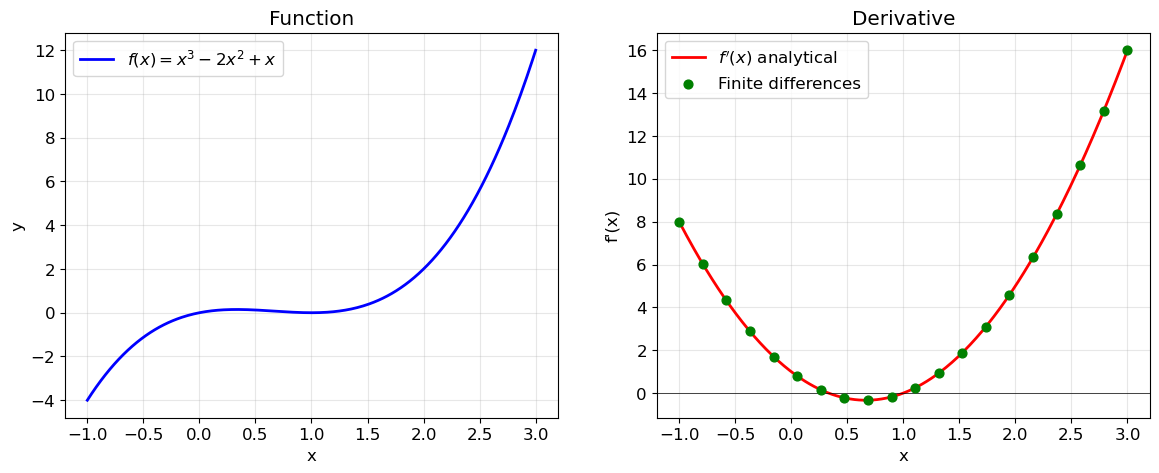

In [3]:
x = np.linspace(-1, 3, 300)

fig, (ax1, ax2) = plt.subplots(1,2,figsize=(14,5))

ax1.plot(x,f(x), 'b-', linewidth=2, label='$f(x) = x^3 - 2x^2 + x$')
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_title("Function")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(x, f_prime_analytical(x), 'r-', linewidth=2, label="$f'(x)$ analytical")
x_sparse = np.linspace(-1, 3, 20)
fd_vals = [numerical_derivative(f,xi) for xi in x_sparse]
ax2.scatter(x_sparse, fd_vals, c='green', s=40, zorder=5, label='Finite differences')
ax2.axhline(y=0, color='k', linewidth=0.5)
ax2.set_xlabel('x'); ax2.set_ylabel("f'(x)")
ax2.set_title('Derivative'); ax2.legend(); ax2.grid(True, alpha=0.3)

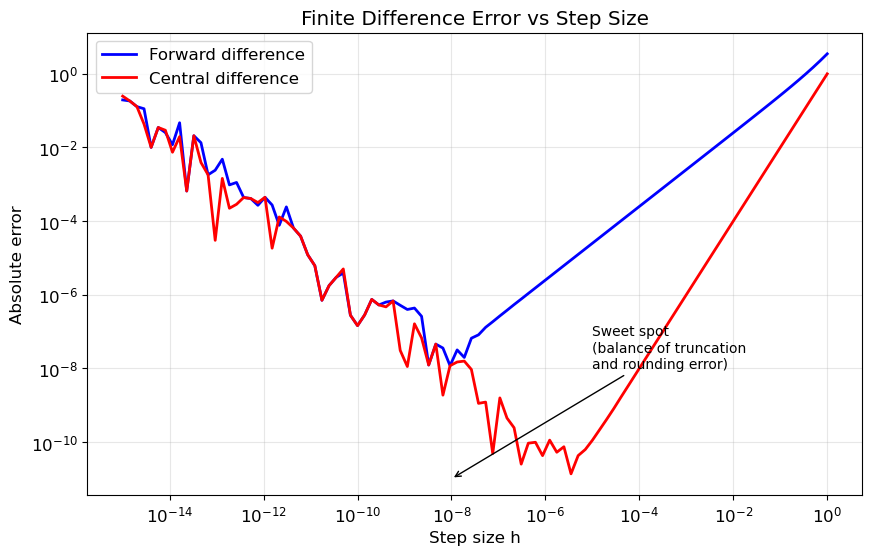

In [4]:
x0 = 1.5
exact = f_prime_analytical(x0)

h_values = np.logspace(-15, 0, 100)

forward_errors = [ abs((f(x0+h) - f(x0))/ h - exact) for h in h_values]
central_errors = [ abs((f(x0+h) - f(x0-h))/(2*h) - exact) for h in h_values]


plt.figure(figsize=(10, 6))
plt.loglog(h_values, forward_errors, 'b-', label='Forward difference', linewidth=2)
plt.loglog(h_values, central_errors, 'r-', label='Central difference', linewidth=2)
plt.xlabel('Step size h')
plt.ylabel('Absolute error')
plt.title('Finite Difference Error vs Step Size')
plt.legend()
plt.grid(True, alpha=0.3, which='both')
plt.annotate('Sweet spot\n(balance of truncation\nand rounding error)',
             xy=(1e-8, 1e-11), fontsize=10,
             arrowprops=dict(arrowstyle='->', color='black'),
             xytext=(1e-5, 1e-8))
plt.show()

In [7]:
x = torch.tensor(2.0, requires_grad=True)
y = x**3 - 2*x**2 + x

dy_dx = torch.autograd.grad(y,x, create_graph=True)[0]
print(f"f(2)   = {y.item():.4f}")
print(f"f'(2)  = {dy_dx.item():.4f}  (analytical: {3*4 - 4*2 + 1})")

d2y_dx2 = torch.autograd.grad(dy_dx,x, create_graph=True)[0]
print(f"f''(2) = {d2y_dx2.item():.4f}  (analytical: {6*2 - 4})")

d3y_dx3 = torch.autograd.grad(d2y_dx2,x, create_graph=True)[0]
print(f"f'''(2)= {d3y_dx3.item():.4f}  (analytical: 6)")

f(2)   = 2.0000
f'(2)  = 5.0000  (analytical: 5)
f''(2) = 8.0000  (analytical: 8)
f'''(2)= 6.0000  (analytical: 6)
